# 07 数据读写、导出与绘图

这一层是「工程接口」，不产生新结论，但决定分析能不能落地：

| 子包 | 用途 | 依赖 |
| --- | --- | --- |
| `honet.io` | 从 CSV / pickle / shapefile 读表 | `honet[pandas]` / `honet[viz]` |
| `honet.export` | 表格导出成 CSV / Excel / LaTeX | `honet[pandas]` / `honet[excel]` |
| `honet.plot` | 把结果画成图 | `honet[viz]` |

本 notebook 全程使用**临时目录**，不会污染你的工作区。

In [1]:
import shutil
import tempfile
from pathlib import Path

import hypernetx as hnx
import matplotlib.pyplot as plt
import pandas as pd

import honet

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

# 所有临时文件都放这里，notebook 结束时自动清理
WORKDIR = Path(tempfile.mkdtemp(prefix="honet_io_demo_"))
print("临时目录:", WORKDIR)

临时目录: D:\TEMP\honet_io_demo_zjqumf18


## 1. 读表：`honet.io`

四个读取函数的区别只在**数据形态**，分派规则很简单：

| 函数 | 读什么 | 分派规则 |
| --- | --- | --- |
| `load_edge_data` | 超边成员表 | `.pkl` → pickle，其它 → CSV |
| `load_weight_data` | 权重表 | 同上 |
| `load_hypergraph_data` | 一次读两张表 | 可只给 `e`，也可给 `e` + `w` |
| `load_map_data` | 地理边界 | 需要 geopandas |

先造一份数据。真实场景下这些是外部文件，这里现场写出来方便复现。

In [2]:
# 超边成员表：一行 = 某条超边包含某个成员
edges_df = pd.DataFrame(
    {
        "agreement": ["A1", "A1", "A1", "A2", "A2"],
        "country": ["CN", "JP", "KR", "CN", "DE"],
        "depth": [3, 3, 3, 2, 2],
    }
)
# 权重表：一行 = 某条超边的权重
weights_df = pd.DataFrame(
    {
        "agreement": ["A1", "A2"],
        "primaryValue": [3.0, 2.0],
    }
)

edges_path = WORKDIR / "edges.csv"
weights_path = WORKDIR / "weights.pkl"

edges_df.to_csv(edges_path, index=False)
weights_df.to_pickle(weights_path)
print("已写出:", edges_path.name, weights_path.name)

已写出: edges.csv weights.pkl


In [3]:
loaded_edges = honet.io.load_edge_data(edges_path)
print("load_edge_data ->")
print(loaded_edges.to_string(index=False))
print("形状:", loaded_edges.shape)

# pickle 也走同一个入口，按扩展名自动分派
loaded_weights = honet.io.load_weight_data(weights_path)
print("\nload_weight_data（pickle）->")
print(loaded_weights.to_string(index=False))

load_edge_data ->
agreement country  depth
       A1      CN      3
       A1      JP      3
       A1      KR      3
       A2      CN      2
       A2      DE      2
形状: (5, 3)

load_weight_data（pickle）->
agreement  primaryValue
       A1           3.0
       A2           2.0


`load_hypergraph_data` 是"一次读两张表"的便捷入口。
只给 `e` 时返回单张表，给 `e` + `w` 时返回二元组——**返回类型会变**，
取值前要先判断。

In [4]:
single = honet.io.load_hypergraph_data(edges_path)
print("只给 e -> 返回类型:", type(single).__name__)

pair = honet.io.load_hypergraph_data(edges_path, weights_path)
print("给 e + w -> 返回类型:", type(pair).__name__, "| 长度:", len(pair))
e_loaded, w_loaded = pair
print("  e 形状:", e_loaded.shape, "| w 形状:", w_loaded.shape)

只给 e -> 返回类型: DataFrame
给 e + w -> 返回类型: tuple | 长度: 2
  e 形状: (5, 3) | w 形状: (2, 2)


### 缺失文件会抛异常，不是静默返回空表

这是与旧库的一个刻意差异：旧实现打印一行提示后返回空 DataFrame，
空表会继续流向下游，最终变成一个莫名其妙的空结果。

In [5]:
try:
    honet.io.load_edge_data(WORKDIR / "does_not_exist.csv")
except FileNotFoundError as exc:
    print("如期抛出 FileNotFoundError:", exc)

如期抛出 FileNotFoundError: 超边数据文件不存在：D:\TEMP\honet_io_demo_zjqumf18\does_not_exist.csv


## 2. 导出：`honet.export`

| 函数 | 输出 |
| --- | --- |
| `to_latex` | LaTeX 表格字符串（直接贴进论文） |
| `beautify_global_metrics` | 把指标表美化后写盘（CSV / Excel / LaTeX） |
| `load_global_metrics` | 读回美化后的指标表 |
| `beautify_honcommunity` / `load_honcommunity` | 社区划分的写 / 读 |

先造一张指标表——真实用法里它来自 `honet.metrics` 的计算结果。

In [6]:
metrics_df = pd.DataFrame(
    {
        "指标": ["度分布熵", "可约性", "自然连通度"],
        "数值": [2.4709, 0.3142, 1.8734],
    }
)
print(metrics_df.to_string(index=False))

latex = honet.export.to_latex(metrics_df, caption_cn="高阶结构指标", label="tab:metrics")
print("\nLaTeX 输出:")
print(latex)

   指标     数值
 度分布熵 2.4709
  可约性 0.3142
自然连通度 1.8734

LaTeX 输出:
\begin{center}
	\bicaption[table]{高阶结构指标}{}
	{\small
		\setlength{\tabcolsep}{4pt}
		\renewcommand{\arraystretch}{1.2}
		\begin{tabular}{l*{1}{c}}
			\hline
			指标 & 数值 \\
			\hline
			度分布熵 & 2.471 \\
			可约性 & 0.314 \\
			自然连通度 & 1.873 \\
			\hline
		\end{tabular}
	}
	\label{tab:metrics}
\end{center}



写盘支持多种格式，`ext` 决定用哪个：

In [7]:
for ext in ("csv", "excel"):
    out = honet.export.beautify_global_metrics(metrics_df, WORKDIR / "metrics", ext=ext)
    size = Path(out).stat().st_size
    print(f"ext={ext:5s} -> {Path(out).name} ({size} 字节)")

ext=csv   -> metrics.csv (78 字节)


ext=excel -> metrics.xlsx (5054 字节)


读回来验证往返一致：

In [8]:
for ext in ("csv", "excel"):
    back = honet.export.load_global_metrics(WORKDIR / "metrics", ext=ext)
    print(f"读回 {ext}:")
    print(back.to_string(index=False))
    print()

读回 csv:
   指标     数值
 度分布熵 2.4709
  可约性 0.3142
自然连通度 1.8734

读回 excel:
   指标     数值
 度分布熵 2.4709
  可约性 0.3142
自然连通度 1.8734



## 3. 绘图：`honet.plot`

这些函数都是「接收计算结果，返回 `Axes`」的薄封装，方便嵌入自己的画布。
好处是不用每次重写一遍坐标轴设置。

先准备一份传播数据：

In [9]:
H = hnx.Hypergraph(
    {
        "a1": ["a", "b", "c"],
        "a2": ["a", "b"],
        "b1": ["c", "d"],
        "b2": ["d", "e", "f"],
    }
)

t, n_sus, n_inf = honet.contagion.random_discrete_sis(
    H, tau={2: 0.3, 3: 0.6}, gamma=0.3, rho=0.2, tmax=40, dt=1.0, seed=1
)
print("传播数据点数:", len(t))

传播数据点数: 41


`draw_sis(S, I, t)` 的**参数顺序是 S, I, t**，不是 t 在前。
这是很容易搞错的地方——传反了不会报错，只会画出一张奇怪的图。

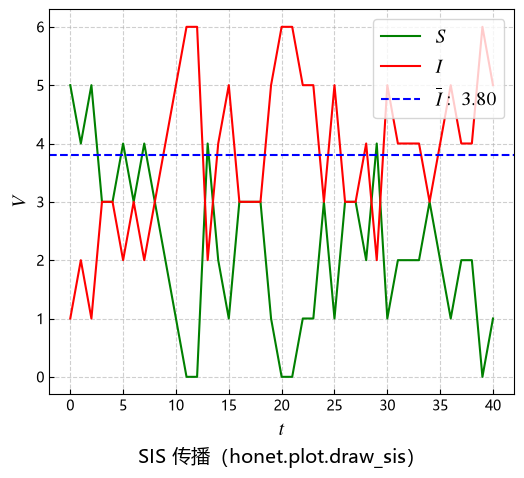

<Figure size 800x800 with 0 Axes>

返回类型: Axes
说明: 函数返回 Axes，方便你继续在上面加东西


In [10]:
ax = honet.plot.draw_sis(n_sus, n_inf, t, title="SIS 传播（honet.plot.draw_sis）")
plt.tight_layout()
plt.show()

print("返回类型:", type(ax).__name__)
print("说明: 函数返回 Axes，方便你继续在上面加东西")

可以传自己的 `ax`，把多张图拼在一起：

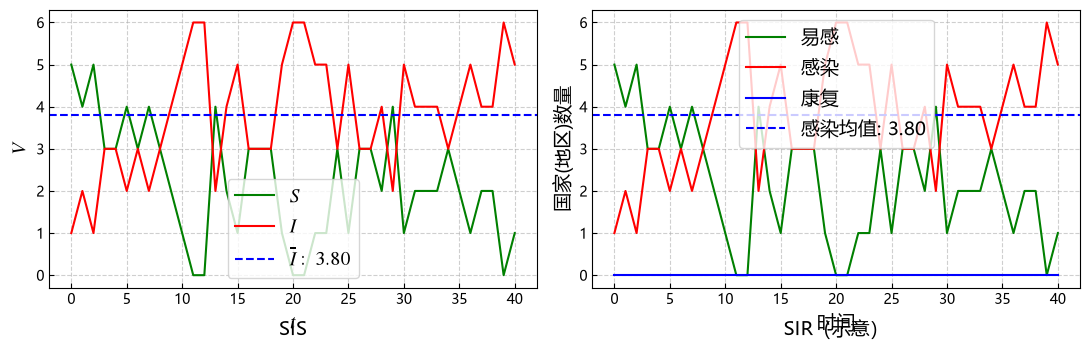

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

honet.plot.draw_sis(n_sus, n_inf, t, title="SIS", ax=axes[0])
honet.plot.draw_sir(n_sus, n_inf, [0] * len(t), t, title="SIR（示意）", ax=axes[1])

plt.tight_layout()
plt.show()

攻击曲线也能直接画——`draw_attack_results` 吃的正是
`execute_attack` 的返回值：

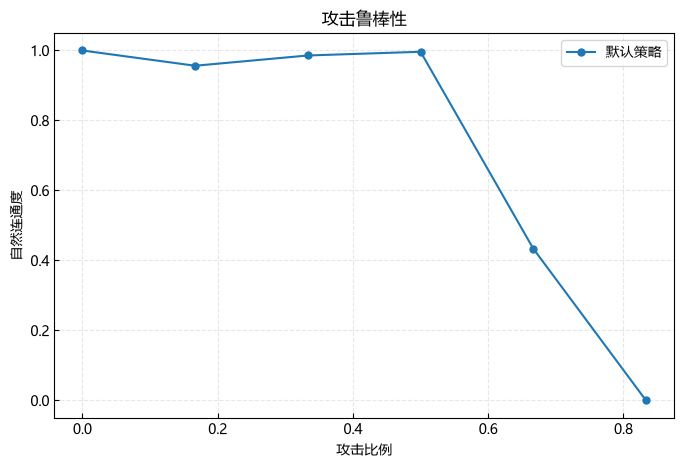

<Figure size 800x800 with 0 Axes>

In [12]:
seq = honet.attack.degree_attack_sequence(H, target="node")
attack_result = honet.attack.execute_attack(H, seq, target="node")

ax = honet.plot.draw_attack_results(attack_result, title="攻击鲁棒性")
plt.tight_layout()
plt.show()

社区划分可视化需要 `nodemap` 形式（`[[社区0成员], [社区1成员], ...]`）：

社区: [['a', 'b'], ['c', 'd', 'e', 'f']]


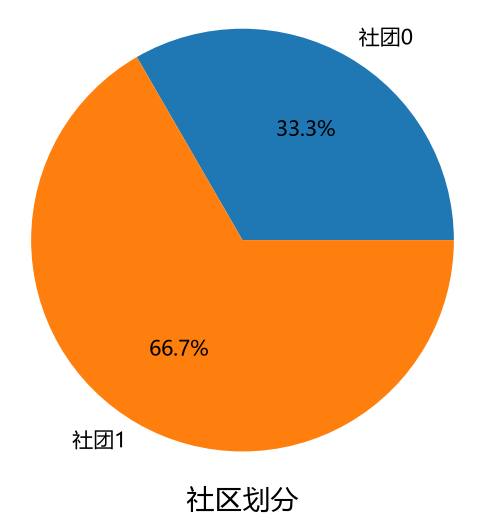

<Figure size 800x800 with 0 Axes>

In [13]:
partition = honet.community.extract_community_partition(H)
communities = [sorted(c) for c in partition["communities"]]
print("社区:", communities)

ax = honet.plot.draw_community_partition(communities, title="社区划分")
plt.tight_layout()
plt.show()

## 4. 把三块串起来：算 → 存 → 画

真实项目里这三步总是连在一起的。下面是一个最小闭环：

In [14]:
# 1) 算：从超图算一组全局指标
H_metrics = hnx.Hypergraph({"e1": ["a", "b", "c"], "e2": ["b", "c", "d"], "e3": ["c", "d", "e"]})
computed = pd.DataFrame(
    {
        "指标": ["度分布熵", "可约性", "自然连通度"],
        "数值": [
            honet.metrics.calc_entropy(H_metrics),
            honet.metrics.calc_reducibility(H_metrics),
            honet.metrics.calc_natural_connectivity(H_metrics),
        ],
    }
)
print("1) 算出来:")
print(computed.to_string(index=False))

# 2) 存：写成 CSV 和 LaTeX
saved = honet.export.beautify_global_metrics(computed, WORKDIR / "final", ext="csv")
tex = honet.export.to_latex(computed, caption_cn="全局指标")
print(f"\n2) 已存: {Path(saved).name}（{Path(saved).stat().st_size} 字节）")
print(f"   LaTeX 长度: {len(tex)} 字符")

# 3) 读回并校验
restored = honet.export.load_global_metrics(WORKDIR / "final", ext="csv")
same = restored["数值"].round(6).tolist() == computed["数值"].round(6).tolist()
print(f"\n3) 读回校验: 数值一致 = {same}")

1) 算出来:
   指标       数值
 度分布熵 1.522955
  可约性 1.000000
自然连通度 1.469814

2) 已存: final.csv（99 字节）
   LaTeX 长度: 274 字符

3) 读回校验: 数值一致 = True


## 小结

| 需求 | 用哪个 |
| --- | --- |
| 读超边 / 权重表 | `load_edge_data` / `load_weight_data` |
| 一次读两张表 | `load_hypergraph_data(e, w)`（注意返回类型会变） |
| 读地理边界 | `load_map_data`（需 geopandas） |
| 导出 LaTeX | `to_latex(df, caption_cn=..., label=...)` |
| 指标表写盘 | `beautify_global_metrics(df, path, ext="csv"/"excel"/"latex")` |
| 读回指标表 | `load_global_metrics(path, ext=...)` |
| 画传播曲线 | `draw_sis(S, I, t)` / `draw_sir(S, I, R, t)` |
| 画攻击曲线 | `draw_attack_results(result)` |
| 画社区 | `draw_community_partition(communities)` |

**三条关键提醒**：

1. **`draw_sis` 的参数顺序是 `(S, I, t)`**，时间在最后。传反了不报错，
   只会画出错误的图——这类错误最难发现。
2. **`load_hypergraph_data` 的返回类型随参数变**：只给 `e` 返回 DataFrame，
   给 `e` + `w` 返回二元组。用之前先判断。
3. **文件不存在会抛 `FileNotFoundError`**，不会静默返回空表。
   这是刻意的设计——空表流向下游比报错危险得多。

In [15]:
# 清理临时目录（notebook 里演示用；真实项目别随手删数据）
shutil.rmtree(WORKDIR, ignore_errors=True)
print("已清理临时目录:", WORKDIR)

已清理临时目录: D:\TEMP\honet_io_demo_zjqumf18
